# Step 02 — EDA & Data Quality

**Tujuan:** Memahami distribusi fraud, pola transaksi, kualitas data, dan sinyal fitur yang paling kuat.

---

## 2.1 Setup

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.4f}'.format)

FRAUD_COLOR    = '#E84C4C'
NONFRAUD_COLOR = '#4C9BE8'

print('Setup done ✓')

Setup done ✓


In [2]:
%%time
df = pd.read_parquet('../data/processed/train_merged.parquet')
print(f'Loaded: {df.shape[0]:,} rows × {df.shape[1]} cols')

# Time features dibuat di sini supaya fraud/nonfraud subset ikut punya kolom ini
df['hour']        = (df['TransactionDT'] // 3600) % 24
df['day']         = df['TransactionDT'] // (3600 * 24)
df['day_of_week'] = df['day'] % 7

fraud    = df[df['isFraud'] == 1]
nonfraud = df[df['isFraud'] == 0]
print(f'Fraud   : {len(fraud):,} ({len(fraud)/len(df)*100:.2f}%)')
print(f'Non-fraud: {len(nonfraud):,} ({len(nonfraud)/len(df)*100:.2f}%)')

Loaded: 590,540 rows × 434 cols


Fraud   : 20,663 (3.50%)
Non-fraud: 569,877 (96.50%)
CPU times: user 2.08 s, sys: 880 ms, total: 2.96 s
Wall time: 1.18 s


---
## 2.2 Pola Waktu Transaksi

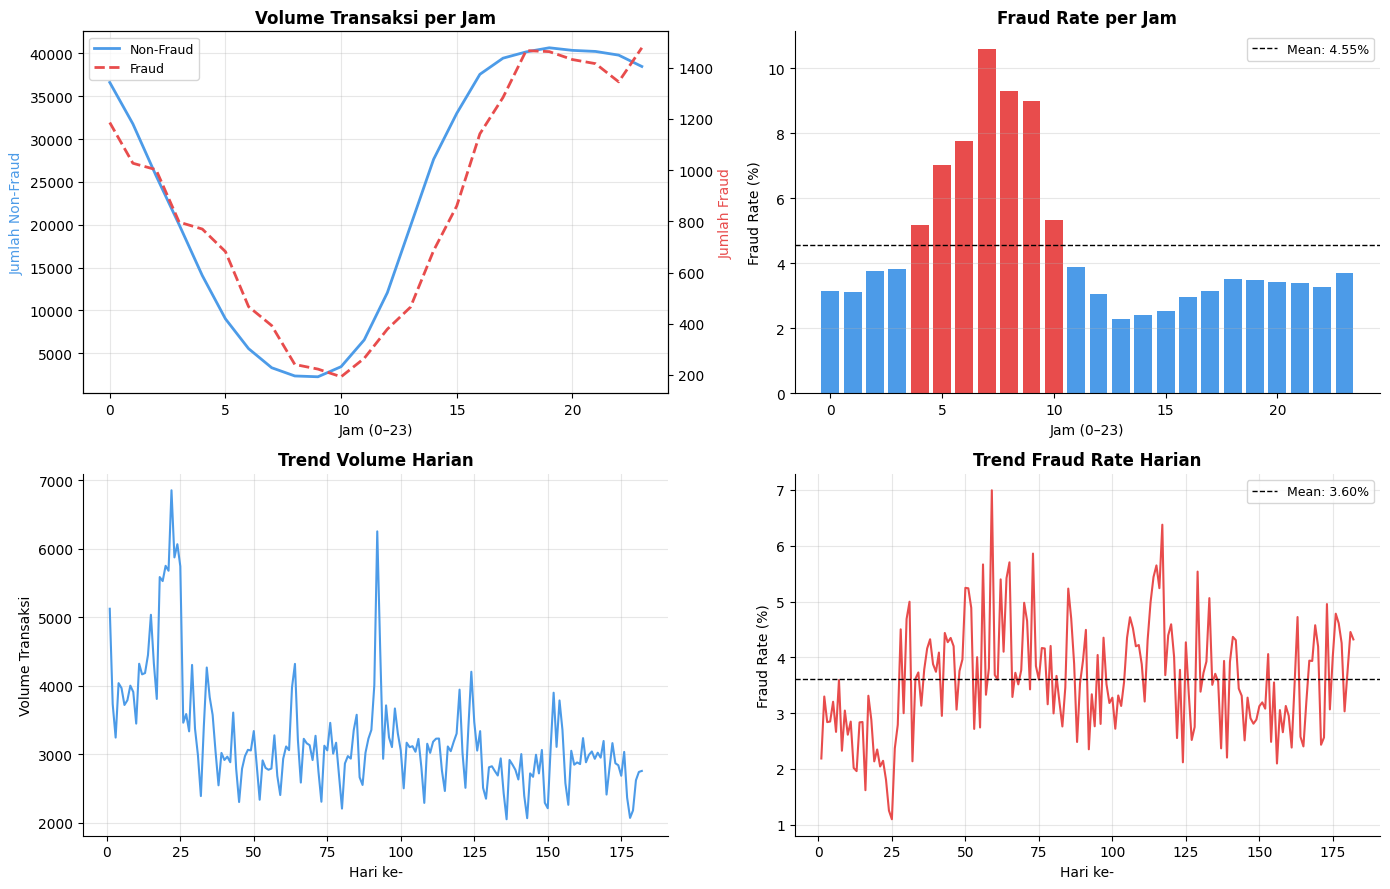

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# --- Volume per jam ---
ax = axes[0, 0]
hour_fraud    = fraud.groupby('hour').size()
hour_nonfraud = nonfraud.groupby('hour').size()
ax.plot(hour_nonfraud.index, hour_nonfraud.values, color=NONFRAUD_COLOR, label='Non-Fraud', linewidth=2)
ax2 = ax.twinx()
ax2.plot(hour_fraud.index, hour_fraud.values, color=FRAUD_COLOR, label='Fraud', linewidth=2, linestyle='--')
ax.set_xlabel('Jam (0–23)')
ax.set_ylabel('Jumlah Non-Fraud', color=NONFRAUD_COLOR)
ax2.set_ylabel('Jumlah Fraud', color=FRAUD_COLOR)
ax.set_title('Volume Transaksi per Jam', fontweight='bold')
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=9)
ax.grid(alpha=0.3)

# --- Fraud rate per jam ---
ax = axes[0, 1]
hourly_fraud_rate = df.groupby('hour')['isFraud'].mean() * 100
ax.bar(hourly_fraud_rate.index, hourly_fraud_rate.values,
       color=[FRAUD_COLOR if r > hourly_fraud_rate.mean() else NONFRAUD_COLOR for r in hourly_fraud_rate.values])
ax.axhline(hourly_fraud_rate.mean(), color='black', linestyle='--', linewidth=1, label=f'Mean: {hourly_fraud_rate.mean():.2f}%')
ax.set_xlabel('Jam (0–23)')
ax.set_ylabel('Fraud Rate (%)')
ax.set_title('Fraud Rate per Jam', fontweight='bold')
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

# --- Volume per hari (trend) ---
ax = axes[1, 0]
daily = df.groupby('day').agg(total=('isFraud','count'), fraud=('isFraud','sum'))
daily['fraud_rate'] = daily['fraud'] / daily['total'] * 100
ax.plot(daily.index, daily['total'], color=NONFRAUD_COLOR, linewidth=1.5)
ax.set_xlabel('Hari ke-')
ax.set_ylabel('Volume Transaksi')
ax.set_title('Trend Volume Harian', fontweight='bold')
ax.grid(alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

# --- Fraud rate per hari ---
ax = axes[1, 1]
ax.plot(daily.index, daily['fraud_rate'], color=FRAUD_COLOR, linewidth=1.5)
ax.axhline(daily['fraud_rate'].mean(), color='black', linestyle='--', linewidth=1,
           label=f'Mean: {daily["fraud_rate"].mean():.2f}%')
ax.set_xlabel('Hari ke-')
ax.set_ylabel('Fraud Rate (%)')
ax.set_title('Trend Fraud Rate Harian', fontweight='bold')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('../reports/figures/02_time_patterns.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 2.3 TransactionAmt — Analisis Mendalam

In [4]:
print('TransactionAmt — statistik deskriptif:')
amt_stats = df.groupby('isFraud')['TransactionAmt'].describe().T
amt_stats.columns = ['Non-Fraud', 'Fraud']
print(amt_stats.to_string())

TransactionAmt — statistik deskriptif:
        Non-Fraud      Fraud
count 569877.0000 20663.0000
mean     134.5117   149.2448
std      239.3951   232.2122
min        0.2510     0.2920
25%       43.9700    35.0440
50%       68.5000    75.0000
75%      120.0000   161.0000
max    31937.3910  5191.0000


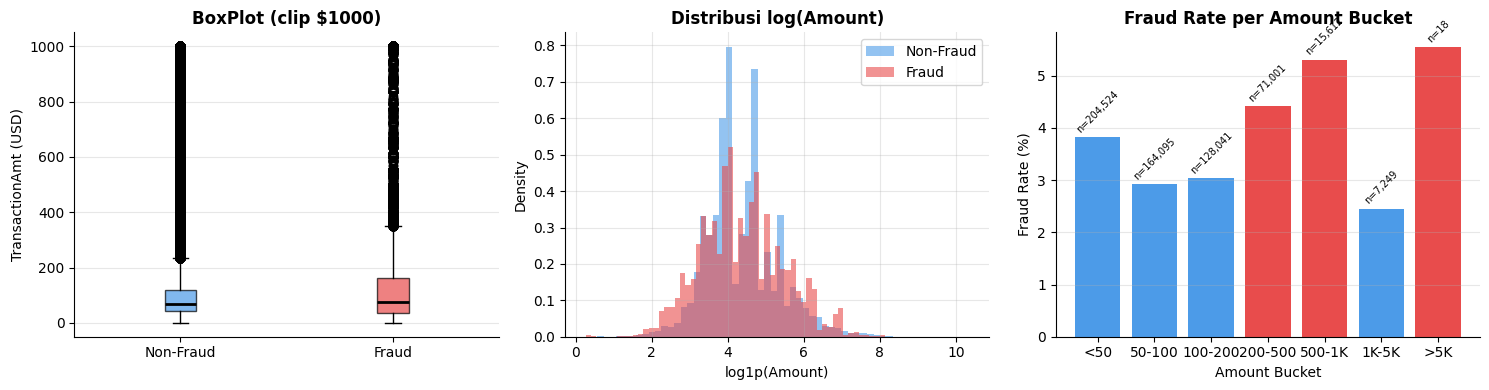

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Boxplot
ax = axes[0]
data_box = [nonfraud['TransactionAmt'].clip(upper=1000),
            fraud['TransactionAmt'].clip(upper=1000)]
bp = ax.boxplot(data_box, patch_artist=True, labels=['Non-Fraud', 'Fraud'],
                medianprops=dict(color='black', linewidth=2))
for patch, color in zip(bp['boxes'], [NONFRAUD_COLOR, FRAUD_COLOR]):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.set_title('BoxPlot (clip $1000)', fontweight='bold')
ax.set_ylabel('TransactionAmt (USD)')
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

# Histogram log scale
ax = axes[1]
ax.hist(np.log1p(nonfraud['TransactionAmt']), bins=60, alpha=0.6,
        color=NONFRAUD_COLOR, label='Non-Fraud', density=True)
ax.hist(np.log1p(fraud['TransactionAmt']), bins=60, alpha=0.6,
        color=FRAUD_COLOR, label='Fraud', density=True)
ax.set_xlabel('log1p(Amount)')
ax.set_ylabel('Density')
ax.set_title('Distribusi log(Amount)', fontweight='bold')
ax.legend()
ax.grid(alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

# Fraud rate per amount bucket
ax = axes[2]
df['amt_bucket'] = pd.cut(df['TransactionAmt'],
                           bins=[0, 50, 100, 200, 500, 1000, 5000, np.inf],
                           labels=['<50', '50-100', '100-200', '200-500', '500-1K', '1K-5K', '>5K'])
bucket_rate = df.groupby('amt_bucket', observed=True)['isFraud'].mean() * 100
bucket_cnt  = df.groupby('amt_bucket', observed=True).size()
bars = ax.bar(bucket_rate.index, bucket_rate.values,
              color=[FRAUD_COLOR if r > bucket_rate.mean() else NONFRAUD_COLOR for r in bucket_rate.values])
for bar, cnt in zip(bars, bucket_cnt.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
            f'n={cnt:,}', ha='center', va='bottom', fontsize=7, rotation=45)
ax.set_xlabel('Amount Bucket')
ax.set_ylabel('Fraud Rate (%)')
ax.set_title('Fraud Rate per Amount Bucket', fontweight='bold')
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('../reports/figures/02_transaction_amount_deep.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 2.4 Fitur Kategorikal — Fraud Rate

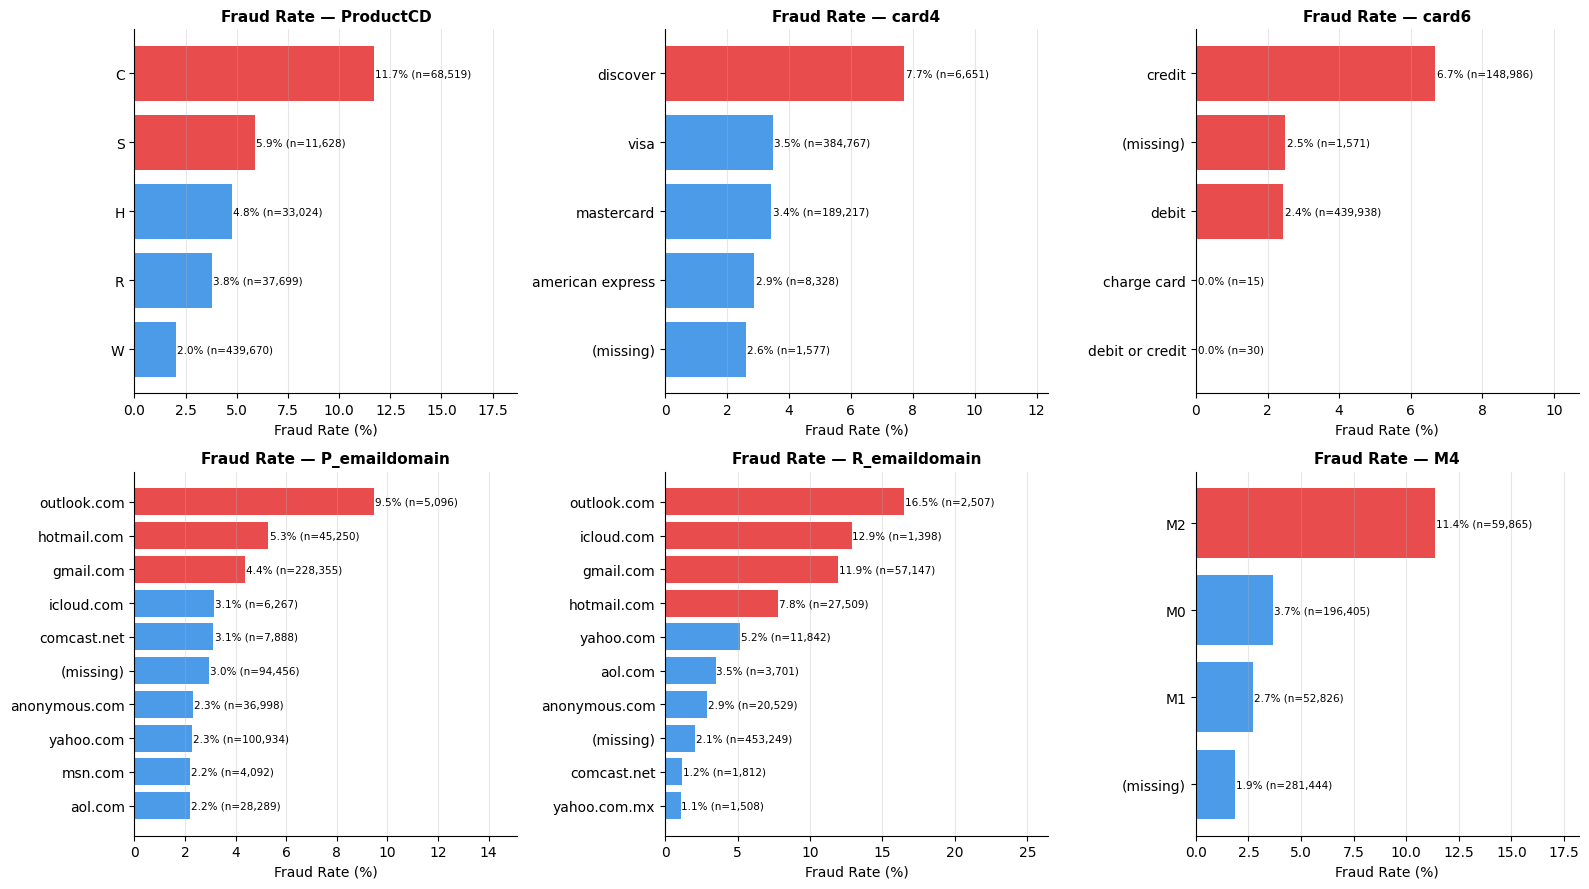

In [6]:
cat_cols = ['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain', 'M4']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, col in zip(axes, cat_cols):
    if col not in df.columns:
        ax.set_visible(False)
        continue

    stats = df.groupby(col, dropna=False).agg(
        count=('isFraud', 'count'),
        fraud_rate=('isFraud', 'mean')
    ).reset_index()
    stats[col] = stats[col].fillna('(missing)').astype(str)
    stats['fraud_rate'] *= 100
    # Top 10 by count
    stats = stats.nlargest(10, 'count').sort_values('fraud_rate', ascending=True)

    colors = [FRAUD_COLOR if r > stats['fraud_rate'].mean() else NONFRAUD_COLOR
              for r in stats['fraud_rate']]
    bars = ax.barh(stats[col].astype(str), stats['fraud_rate'], color=colors)
    for bar, (_, row) in zip(bars, stats.iterrows()):
        ax.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
                f'{row["fraud_rate"]:.1f}% (n={row["count"]:,})',
                va='center', fontsize=7.5)
    ax.set_title(f'Fraud Rate — {col}', fontweight='bold', fontsize=11)
    ax.set_xlabel('Fraud Rate (%)')
    ax.set_xlim(0, stats['fraud_rate'].max() * 1.6)
    ax.grid(axis='x', alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('../reports/figures/02_categorical_fraud_rate.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 2.5 Email Domain — Top Fraud Domains

In [7]:
for col in ['P_emaildomain', 'R_emaildomain']:
    stats = df.groupby(col)['isFraud'].agg(['count', 'mean']).reset_index()
    stats.columns = [col, 'count', 'fraud_rate']
    stats['fraud_rate'] *= 100
    # Filter domain yang cukup sering muncul
    stats = stats[stats['count'] > 500].sort_values('fraud_rate', ascending=False)

    print(f'\nTop 10 fraud domains — {col}:')
    print(stats.head(10).to_string(index=False))


Top 10 fraud domains — P_emaildomain:
P_emaildomain  count  fraud_rate
     mail.com    559     18.9624
  outlook.com   5096      9.4584
  live.com.mx    749      5.4740
  hotmail.com  45250      5.2950
    gmail.com 228355      4.3542
   icloud.com   6267      3.1434
  comcast.net   7888      3.1187
  charter.net    816      3.0637
bellsouth.net   1909      2.7763
     live.com   3041      2.7622

Top 10 fraud domains — R_emaildomain:
R_emaildomain  count  fraud_rate
  outlook.com   2507     16.5138
   icloud.com   1398     12.8755
    gmail.com  57147     11.9184
  hotmail.com  27509      7.7793
  live.com.mx    754      5.8355
    yahoo.com  11842      5.1512
     live.com    762      4.9869
      aol.com   3701      3.4855
anonymous.com  20529      2.9130
       me.com    556      1.9784


---
## 2.6 Card Features

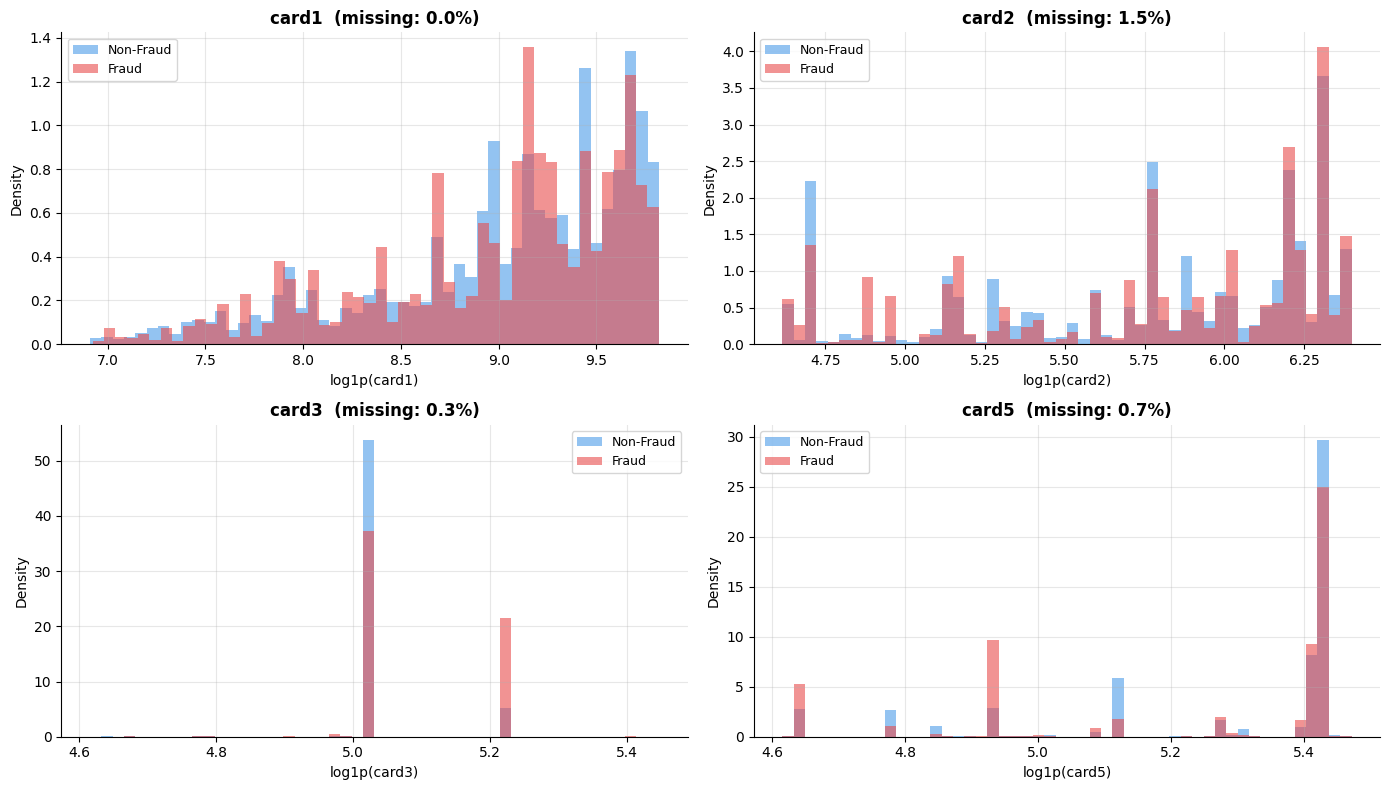

In [8]:
card_num_cols = ['card1', 'card2', 'card3', 'card5']

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for ax, col in zip(axes, card_num_cols):
    ax.hist(np.log1p(nonfraud[col].dropna()), bins=50, alpha=0.6,
            color=NONFRAUD_COLOR, label='Non-Fraud', density=True)
    ax.hist(np.log1p(fraud[col].dropna()), bins=50, alpha=0.6,
            color=FRAUD_COLOR, label='Fraud', density=True)
    miss_pct = df[col].isnull().mean() * 100
    ax.set_title(f'{col}  (missing: {miss_pct:.1f}%)', fontweight='bold')
    ax.set_xlabel(f'log1p({col})')
    ax.set_ylabel('Density')
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('../reports/figures/02_card_features.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 2.7 M-Features (Match Flags)

In [9]:
m_cols = [c for c in df.columns if c.startswith('M') and df[c].dtype == 'object']
print(f'M-features: {m_cols}')

m_stats = []
for col in m_cols:
    for val in df[col].dropna().unique():
        sub = df[df[col] == val]
        m_stats.append({
            'feature': col, 'value': val,
            'count': len(sub),
            'fraud_rate': sub['isFraud'].mean() * 100
        })

m_df = pd.DataFrame(m_stats)
print()
print(m_df.sort_values(['feature', 'value']).to_string(index=False))

M-features: ['M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9']



feature value  count  fraud_rate
     M1     F     25      0.0000
     M1     T 319415      1.9855
     M2     F  33972      3.4852
     M2     T 285468      1.8069
     M3     F  67709      3.0262
     M3     T 251731      1.7054
     M4    M0 196405      3.6649
     M4    M1  52826      2.7051
     M4    M2  59865     11.3739
     M5     F 132491      2.6523
     M5     T 107567      3.7697
     M6     F 227856      2.3686
     M6     T 193324      1.7044
     M7     F 211374      1.9345
     M7     T  32901      2.2127
     M8     F 155251      2.1726
     M8     T  89037      1.6218
     M9     F  38632      3.0001
     M9     T 205656      1.7787


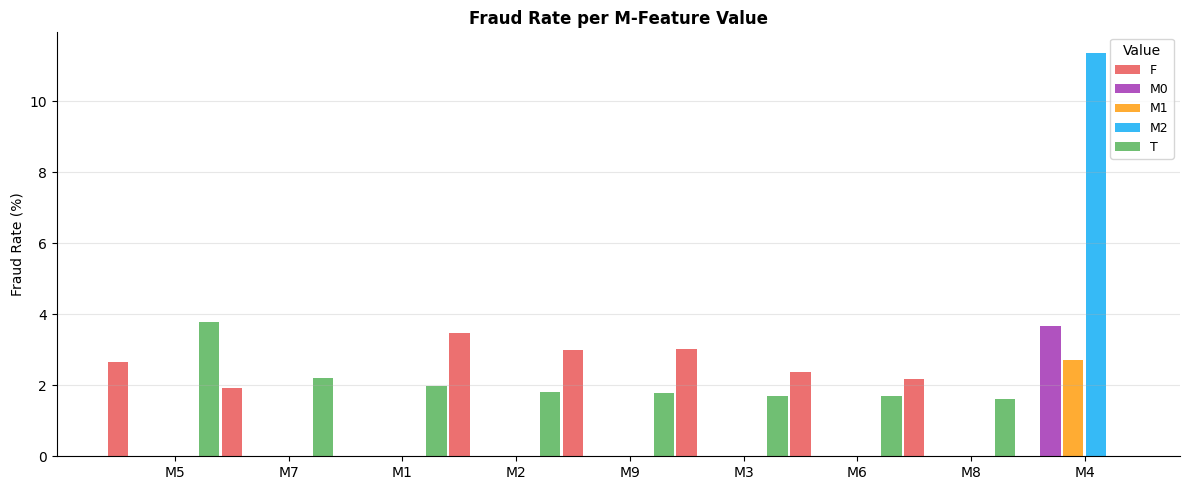

In [10]:
fig, ax = plt.subplots(figsize=(12, 5))

m_pivot = m_df.pivot(index='feature', columns='value', values='fraud_rate')
m_pivot_sorted = m_pivot.sort_values('T', ascending=False) if 'T' in m_pivot.columns else m_pivot

x = np.arange(len(m_pivot_sorted))
width = 0.35
colors_map = {'T': '#4CAF50', 'F': FRAUD_COLOR, 'M0': '#9C27B0', 'M1': '#FF9800', 'M2': '#03A9F4'}

for i, col in enumerate(m_pivot_sorted.columns):
    vals = m_pivot_sorted[col].fillna(0)
    offset = (i - len(m_pivot_sorted.columns)/2) * 0.2
    ax.bar(x + offset, vals, 0.18, label=col,
           color=colors_map.get(col, f'C{i}'), alpha=0.8)

ax.set_xticks(x)
ax.set_xticklabels(m_pivot_sorted.index)
ax.set_ylabel('Fraud Rate (%)')
ax.set_title('Fraud Rate per M-Feature Value', fontweight='bold')
ax.legend(title='Value', fontsize=9)
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('../reports/figures/02_m_features.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 2.8 C-Features & D-Features — Korelasi dengan Target

In [11]:
# Top C-features & D-features paling berkorelasi dengan isFraud
c_cols = [c for c in df.columns if c.startswith('C') and pd.api.types.is_numeric_dtype(df[c])]
d_cols = [c for c in df.columns if c.startswith('D') and pd.api.types.is_numeric_dtype(df[c])]

c_corr = df[c_cols + ['isFraud']].corr(numeric_only=True)['isFraud'].drop('isFraud').abs().sort_values(ascending=False)
d_corr = df[d_cols + ['isFraud']].corr(numeric_only=True)['isFraud'].drop('isFraud').abs().sort_values(ascending=False)

print(f'C-features (numerik): {len(c_cols)} kolom')
print('Top 10 C-features by |correlation| dengan isFraud:')
print(c_corr.head(10).to_string())
print(f'\nD-features (numerik): {len(d_cols)} kolom')
print('Top 10 D-features by |correlation| dengan isFraud:')
print(d_corr.head(10).to_string())

C-features (numerik): 14 kolom
Top 10 C-features by |correlation| dengan isFraud:
C2    0.0372
C8    0.0321
C12   0.0319
C9    0.0317
C5    0.0308
C1    0.0306
C4    0.0304
C10   0.0284
C7    0.0282
C11   0.0275

D-features (numerik): 15 kolom
Top 10 D-features by |correlation| dengan isFraud:
D8    0.1426
D7    0.1272
D2    0.0836
D15   0.0775
D10   0.0720
D4    0.0672
D1    0.0672
D5    0.0646
D13   0.0594
D6    0.0572


---
## 2.9 V-Features — Mana yang Paling Berguna?

In [12]:
v_cols = [c for c in df.columns if c.startswith('V')]
print(f'Total V-features: {len(v_cols)}')

# Filter V yang tidak >90% missing dulu
v_valid = [c for c in v_cols if df[c].isnull().mean() < 0.9]
print(f'V-features dengan <90% missing: {len(v_valid)}')

# Korelasi dengan target
v_corr = df[v_valid + ['isFraud']].corr()['isFraud'].drop('isFraud').abs().sort_values(ascending=False)

print(f'\nTop 15 V-features by |correlation|:')
print(v_corr.head(15).to_string())

Total V-features: 339
V-features dengan <90% missing: 339



Top 15 V-features by |correlation|:
V257   0.3831
V246   0.3669
V244   0.3641
V242   0.3606
V201   0.3280
V200   0.3188
V189   0.3082
V188   0.3036
V258   0.2972
V45    0.2818
V158   0.2781
V156   0.2760
V149   0.2733
V228   0.2689
V44    0.2604


---
## 2.10 Missing Value Strategy

In [13]:
missing = df.isnull().mean().sort_values(ascending=False)

buckets = {
    'Drop (>90% missing)'  : (missing > 0.9).sum(),
    'Impute carefully (50–90%)' : ((missing > 0.5) & (missing <= 0.9)).sum(),
    'Standard impute (<50%)': ((missing > 0) & (missing <= 0.5)).sum(),
    'No missing'           : (missing == 0).sum(),
}

print('Strategi penanganan missing values:')
for strategy, count in buckets.items():
    print(f'  {strategy:35s}: {count:3d} kolom')

print(f'\nRencana:')
print('  - Kolom >90% missing  → drop saat feature engineering')
print('  - Numerik missing     → isi dengan median (robust terhadap outlier)')
print('  - Kategorikal missing → isi dengan "(missing)" sebagai kategori sendiri')
print('  - Flag missing        → tambah kolom _isna sebagai sinyal tambahan')

Strategi penanganan missing values:
  Drop (>90% missing)                :  12 kolom
  Impute carefully (50–90%)          : 202 kolom
  Standard impute (<50%)             : 200 kolom
  No missing                         :  24 kolom

Rencana:
  - Kolom >90% missing  → drop saat feature engineering
  - Numerik missing     → isi dengan median (robust terhadap outlier)
  - Kategorikal missing → isi dengan "(missing)" sebagai kategori sendiri
  - Flag missing        → tambah kolom _isna sebagai sinyal tambahan


---
## 2.11 Ringkasan EDA

| Temuan | Implikasi untuk modeling |
|--------|-------------------------|
| Fraud terjadi lebih banyak di jam malam (0–6) | Tambah fitur `hour` |
| Fraud rate naik untuk amount >$1000 | Tambah fitur amount bucket |
| `card4=discover` punya fraud rate tertinggi | Frequency encoding card features |
| Email domain tertentu sangat berisiko | Frequency encoding email domain |
| M-features: nilai 'F' (false match) → fraud rate tinggi | Encode M-features sebagai numerik |
| C14 paling berkorelasi di C-features | Prioritaskan C14 |
| Banyak V-features >90% missing | Drop dulu, fokus ke yang <50% missing |
| Missing identity data (~57%) bukan noise | Tambah flag `has_identity` |

**Next step → Notebook 03: Feature Engineering**